## **Import Required Packages**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## **Import Dataset**
#### This work can be done in ways, I prefer to use UCI Machine Learning Repository.
#### **Dataset:** UCI Bank Marketing Dataset at - 🔗https://archive.ics.uci.edu/dataset/222/bank+marketing

In [5]:
from ucimlrepo import fetch_ucirepo

bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features 
y = bank_marketing.data.targets

**`Note:`if network did not support this way of calling data by any reason, Run the cell below:**

In [3]:
# df = pd.read_csv("Dataset/Bank Marketting.csv", sep=';')

"Since X and y come from the same source and their indices are identical and unique (verified below), joining them by index is safe."

In [6]:
print(X.index.equals(y.index))

True


In [9]:
df = X.join(y, how='left')
df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
5,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
6,28,management,single,tertiary,no,447,yes,yes,NaN,5,may,217,1,-1,0,NaN,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,NaN,5,may,380,1,-1,0,NaN,no
8,58,retired,married,primary,no,121,yes,no,NaN,5,may,50,1,-1,0,NaN,no
9,43,technician,single,secondary,no,593,yes,no,NaN,5,may,55,1,-1,0,NaN,no


In [8]:
df.replace('unknown', np.nan, inplace=True)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,NaN,no


#### **Some labels are incorrect or unclear**

In [11]:
df = df.rename(columns={'y':'Subscribe', 'day_of_week':'day'})
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,Subscribe
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,NaN,no


## **Dataset Structure**

In [12]:
print(f"\nThe dataset has {df.shape[0]} Records And {df.shape[1]} Features")
print('\n'+100*'.'+'\n')
print(df.dtypes)
print(100*'.'+'\n')
print(df.nunique())
print(100*'.'+'\n')
display(df.describe())
print(100*'.'+'\n')
df.info()


The dataset has 45211 Records And 17 Features

....................................................................................................

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
Subscribe      str
dtype: object
....................................................................................................

age            77
job            11
marital         3
education       3
default         2
balance      7168
housing         2
loan            2
contact         2
day            31
month          12
duration     1573
campaign       48
pdays         559
previous       41
poutcome        3
Subscribe       2
dtype: int64
............................................................................................

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


....................................................................................................

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        44923 non-null  str  
 2   marital    45211 non-null  str  
 3   education  43354 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    32191 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   8252 non-null   str  
 16  Subscribe  45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


#### Duplicated Values

In [57]:
print(df.duplicated().sum())

0


#### Categorical Features

In [13]:
categorical_features = df.select_dtypes(include=['string', 'object'])

In [14]:
categorical_features = df.select_dtypes(include=['string', 'object'])
for feature in categorical_features:
    print(f"Unique values in {feature} are :{df[feature].unique()}")
    print(100*'.'+'\n')

Unique values in job are :<StringArray>
[   'management',    'technician',  'entrepreneur',   'blue-collar',
             nan,       'retired',        'admin.',      'services',
 'self-employed',    'unemployed',     'housemaid',       'student']
Length: 12, dtype: str
....................................................................................................

Unique values in marital are :<StringArray>
['married', 'single', 'divorced']
Length: 3, dtype: str
....................................................................................................

Unique values in education are :<StringArray>
['tertiary', 'secondary', nan, 'primary']
Length: 4, dtype: str
....................................................................................................

Unique values in default are :<StringArray>
['no', 'yes']
Length: 2, dtype: str
....................................................................................................

Unique values in housing are :<S

#### 🚫 Null Values

In [94]:
print(df.isna().sum())

age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64


In [74]:
print("Percentage of missing values per column:")
print(round(df.isna().mean() * 100, 1))

Percentage of missing values per column:
age           0.0
job           0.6
marital       0.0
education     4.1
default       0.0
balance       0.0
housing       0.0
loan          0.0
contact      28.8
day           0.0
month         0.0
duration      0.0
campaign      0.0
pdays         0.0
previous      0.0
poutcome     81.7
Subscribe     0.0
dtype: float64


In [40]:
num_profiling = df.describe().T
num_profiling.drop(axis=1, labels=['count', 'mean', 'std'])
ndf = df.select_dtypes(include='int64')
num_profiling['skewness'] = ndf.skew()

num_profiling

,count,mean,std,min,25%,50%,75%,max,skewness
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0,0.684818
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0,8.360308
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0,0.093079
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0,3.144318
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0,4.898650
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0,2.615715
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0,41.846454


## **Stage 1**
#### Start Feature Engineering

In [41]:
sdf = df[['age', 'balance', 'duration', 'campaign']]

<Axes: xlabel='campaign', ylabel='Count'>

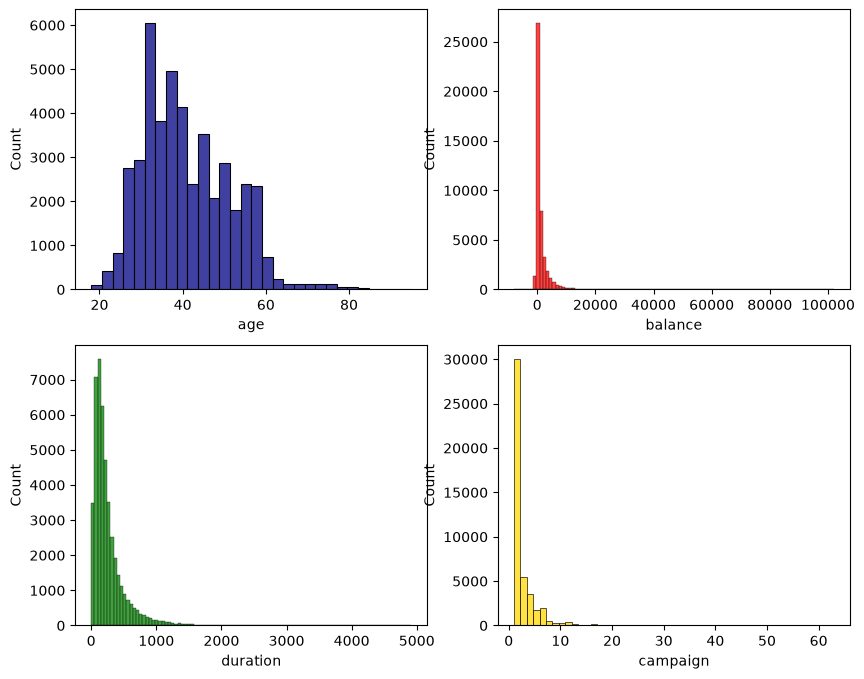

In [83]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
sns.histplot(data=sdf['age'], bins=30, ax=axes[0, 0], color='navy')
sns.histplot(data=sdf['balance'], bins=100, ax=axes[0, 1], color='red')
sns.histplot(data=sdf['duration'], bins=100, ax=axes[1, 0], color='green')
sns.histplot(data=sdf['campaign'], bins=50, ax=axes[1, 1], color='gold')